# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [4]:
#Load the cleaned aviation accident dataset
df = pd.read_csv("data/AviationData_Cleaned.csv")

#Insert the dataset
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())


C:\Users\HP\AppData\Local\Temp\ipykernel_11200\3453509354.py:2: DtypeWarning: Columns (0: Latitude, 1: Longitude, 2: Broad.phase.of.flight) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/AviationData_Cleaned.csv")


Dataset shape: (70852, 34)

First five rows:


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.People,Plan.Type,Plane.Type
0,20001218X45444,Accident,SEA87LA080,1948-10-24,"MOOSE CREEK, ID",United States,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,UNK,CRUISE,Probable Cause,NaN,2.0,STINSON_108-3,STINSON_108-3
1,20001218X45447,Accident,LAX94LA336,1962-07-19,"BRIDGEPORT, CA",United States,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,UNK,UNKNOWN,Probable Cause,19-09-1996,4.0,PIPER_PA24-180,PIPER_PA24-180
2,20061025X01555,Accident,NYC07LA005,1974-08-30,"Saltville, VA",United States,36.922223,-81.878056,NaN,NaN,...,0.0,0.0,0.0,IMC,CRUISE,Probable Cause,26-02-2007,3.0,CESSNA_172M,CESSNA_172M
3,20001218X45448,Accident,LAX96LA321,1977-06-19,"EUREKA, CA",United States,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,IMC,CRUISE,Probable Cause,12-09-2000,2.0,ROCKWELL_112,ROCKWELL_112
4,20041105X01764,Accident,CHI79FA064,1979-08-02,"Canton, OH",United States,NaN,NaN,NaN,NaN,...,2.0,0.0,0.0,VMC,APPROACH,Probable Cause,16-04-1980,3.0,CESSNA_501,CESSNA_501



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 70852 entries, 0 to 70851
Data columns (total 34 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Event.Id                70852 non-null  str    
 1   Investigation.Type      70852 non-null  str    
 2   Accident.Number         70852 non-null  str    
 3   Event.Date              70852 non-null  str    
 4   Location                70814 non-null  str    
 5   Country                 70664 non-null  str    
 6   Latitude                25365 non-null  object 
 7   Longitude               25360 non-null  object 
 8   Airport.Code            39844 non-null  str    
 9   Airport.Name            42087 non-null  str    
 10  Injury.Severity         70581 non-null  str    
 11  Aircraft.damage         69668 non-null  str    
 12  Aircraft.Category       23429 non-null  str    
 13  Registration.Number     69908 non-null  str    
 14  Make                    708

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [6]:
# Separate smaller and larger airplanes using a threshold of 20 people

df["Plane.Size"] = np.where(
    df["Total.People"] <= 20,
    "Smaller Airplanes",
    "Larger Airplanes"
)

#Display the numer of accidents in each group
print("Number of accidents by plane size:")
print(df["Plane.Size"].value_counts())

##Display the first five rows
display(df[["Make", "Model", "Total.People", "Plane.Size"]].head())



Number of accidents by plane size:
Plane.Size
Smaller Airplanes    69624
Larger Airplanes      1228
Name: count, dtype: int64


,Make,Model,Total.People,Plane.Size
0,STINSON,108-3,2.0,Smaller Airplanes
1,PIPER,PA24-180,4.0,Smaller Airplanes
2,CESSNA,172M,3.0,Smaller Airplanes
3,ROCKWELL,112,2.0,Smaller Airplanes
4,CESSNA,501,3.0,Smaller Airplanes


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [9]:
# Check the columns currently available
print(df.columns.tolist())

['Event.Id', 'Investigation.Type', 'Accident.Number', 'Event.Date', 'Location', 'Country', 'Latitude', 'Longitude', 'Airport.Code', 'Airport.Name', 'Injury.Severity', 'Aircraft.damage', 'Aircraft.Category', 'Registration.Number', 'Make', 'Model', 'Amateur.Built', 'Number.of.Engines', 'Engine.Type', 'FAR.Description', 'Schedule', 'Purpose.of.flight', 'Air.carrier', 'Total.Fatal.Injuries', 'Total.Serious.Injuries', 'Total.Minor.Injuries', 'Total.Uninjured', 'Weather.Condition', 'Broad.phase.of.flight', 'Report.Status', 'Publication.Date', 'Total.People', 'Plan.Type', 'Plane.Type', 'Plane.Size']


In [11]:
# Create the fatal/serious injury fraction

df["Fatal.Serious.Injuries"] = (
    df["Total.Fatal.Injuries"] + df["Total.Serious.Injuries"]
)

df["Fatal.Serious.Injury.Rate"] = np.where(
    df["Total.People"] > 0,
    df["Fatal.Serious.Injuries"] / df["Total.People"],
    np.nan
)

print("Fatal/serious injury fraction created successfully!")
print(df[["Make", "Total.People", "Fatal.Serious.Injury.Rate"]].head())

Fatal/serious injury fraction created successfully!
       Make  Total.People  Fatal.Serious.Injury.Rate
0   STINSON           2.0                        1.0
1     PIPER           4.0                        1.0
2    CESSNA           3.0                        1.0
3  ROCKWELL           2.0                        1.0
4    CESSNA           3.0                        1.0


15 makes with the lowest mean injury fraction: Smaller Airplanes


,Plane.Size,Make,Fatal.Serious.Injury.Rate
107,Smaller Airplanes,WACO,0.100473
64,Smaller Airplanes,GRUMMAN-SCHWEIZER,0.111549
67,Smaller Airplanes,HELIO,0.149689
76,Smaller Airplanes,MAULE,0.155395
73,Smaller Airplanes,LET,0.161765
31,Smaller Airplanes,AVIAT AIRCRAFT INC,0.162338
38,Smaller Airplanes,BOEING STEARMAN,0.176471
108,Smaller Airplanes,WEATHERLY,0.180851
37,Smaller Airplanes,BOEING,0.184752
59,Smaller Airplanes,GREAT LAKES,0.189394


15 makes with the lowest mean injury fraction: Larger Airplanes


,Plane.Size,Make,Fatal.Serious.Injury.Rate
0,Larger Airplanes,AERO COMMANDER,0.000000
12,Larger Airplanes,GULFSTREAM,0.000000
17,Larger Airplanes,SIKORSKY,0.000000
18,Larger Airplanes,SWEARINGEN,0.000000
1,Larger Airplanes,AEROSPATIALE,0.066336
15,Larger Airplanes,MCDONNELL DOUGLAS,0.082618
3,Larger Airplanes,AIRBUS INDUSTRIE,0.108301
10,Larger Airplanes,EMBRAER,0.111087
6,Larger Airplanes,BOEING,0.116269
13,Larger Airplanes,LEARJET,0.130435


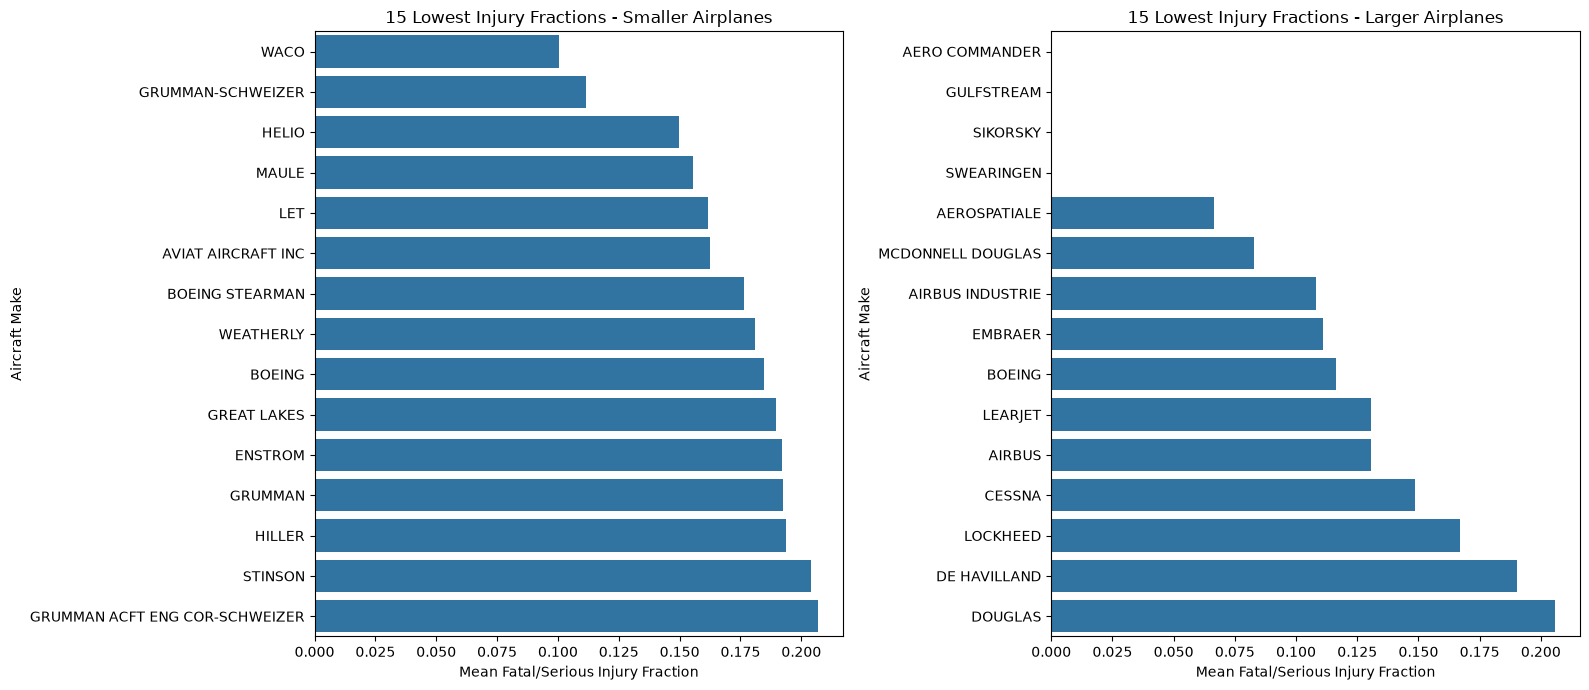

In [14]:

# Analyzing makes: Compare injury risk for smaller and larger airplanes

# Create the fatal/serious injury fraction FIRST
df["Fatal.Serious.Injuries"] = (
    df["Total.Fatal.Injuries"] + df["Total.Serious.Injuries"]
)

df["Fatal.Serious.Injury.Rate"] = np.where(
    df["Total.People"] > 0,
    df["Fatal.Serious.Injuries"] / df["Total.People"],
    np.nan
)

# Calculate the mean injury fraction for each make and plane size
make_risk = (
    df.groupby(["Plane.Size", "Make"])["Fatal.Serious.Injury.Rate"]
    .mean()
    .reset_index()
)

# Find the 15 makes with the lowest mean injury fraction for each group
smallest_risk = (
    make_risk[make_risk["Plane.Size"] == "Smaller Airplanes"]
    .nsmallest(15, "Fatal.Serious.Injury.Rate")
)

largest_risk = (
    make_risk[make_risk["Plane.Size"] == "Larger Airplanes"]
    .nsmallest(15, "Fatal.Serious.Injury.Rate")
)

# Display the results
print("15 makes with the lowest mean injury fraction: Smaller Airplanes")
display(smallest_risk)

print("15 makes with the lowest mean injury fraction: Larger Airplanes")
display(largest_risk)

# Plot the results side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=smallest_risk,
    x="Fatal.Serious.Injury.Rate",
    y="Make",
    ax=axes[0]
)
axes[0].set_title("15 Lowest Injury Fractions - Smaller Airplanes")
axes[0].set_xlabel("Mean Fatal/Serious Injury Fraction")
axes[0].set_ylabel("Aircraft Make")

sns.barplot(
    data=largest_risk,
    x="Fatal.Serious.Injury.Rate",
    y="Make",
    ax=axes[1]
)
axes[1].set_title("15 Lowest Injury Fractions - Larger Airplanes")
axes[1].set_xlabel("Mean Fatal/Serious Injury Fraction")
axes[1].set_ylabel("Aircraft Make")

plt.tight_layout()
plt.show()


**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

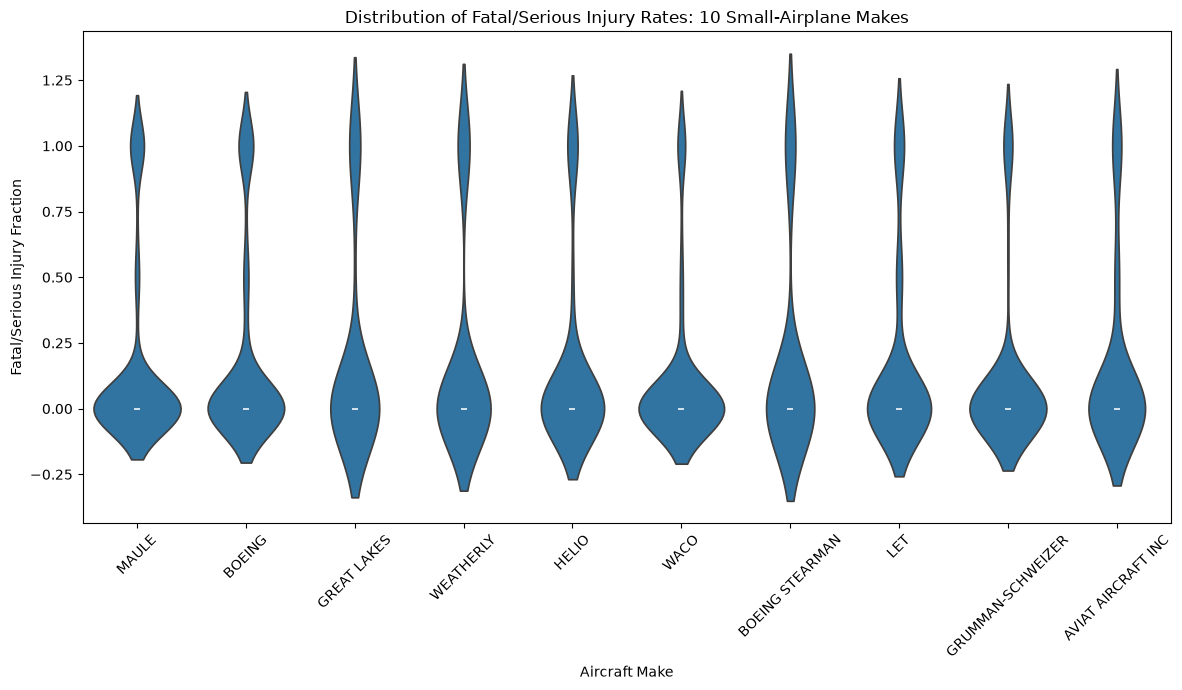

In [18]:

# Distribution of injury rates: Small airplane makes

# Calculate the mean injury rate for each small-airplane make
small_make_risk = (
    df[df["Plane.Size"] == "Smaller Airplanes"]
    .groupby("Make")["Fatal.Serious.Injury.Rate"]
    .mean()
    .reset_index()
)

# Select the 10 makes with the lowest mean injury rates
top_10_small_makes = (
    small_make_risk
    .nsmallest(10, "Fatal.Serious.Injury.Rate")["Make"]
    .tolist()
)

# Keep accident records for those 10 makes
small_make_data = df[
    (df["Plane.Size"] == "Smaller Airplanes") &
    (df["Make"].isin(top_10_small_makes))
].copy()

# Plot the distribution of injury rates
plt.figure(figsize=(12, 7))

sns.violinplot(
    data=small_make_data,
    x="Make",
    y="Fatal.Serious.Injury.Rate"
)

plt.title("Distribution of Fatal/Serious Injury Rates: 10 Small-Airplane Makes")
plt.xlabel("Aircraft Make")
plt.ylabel("Fatal/Serious Injury Fraction")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

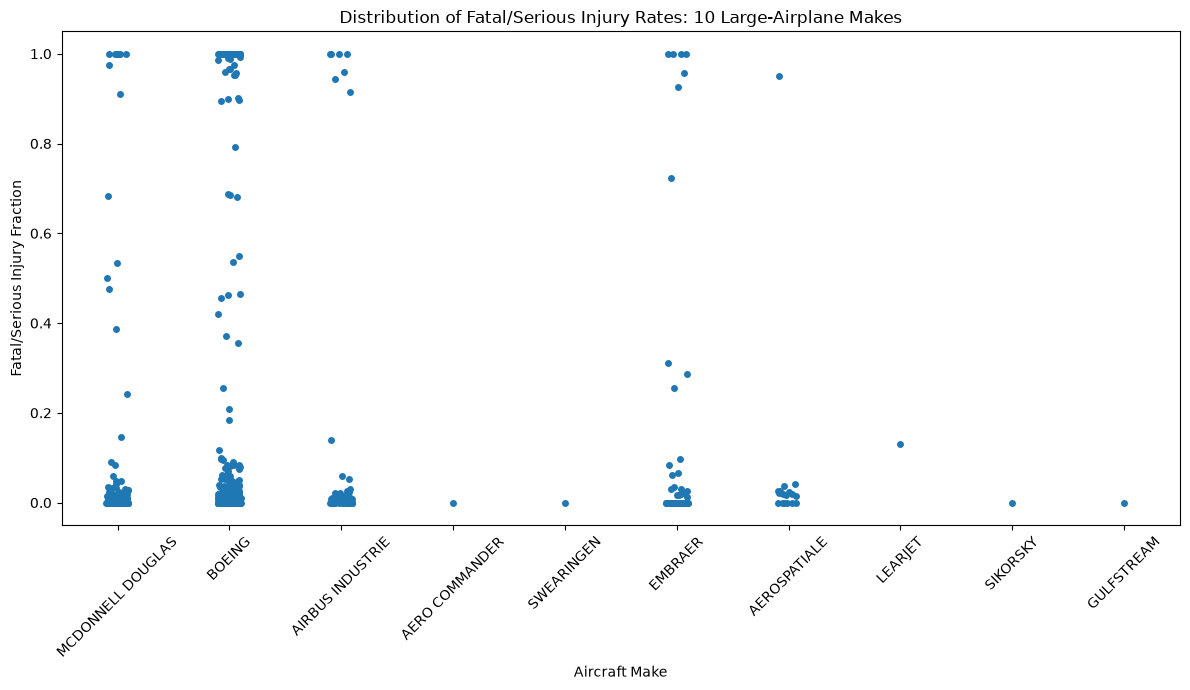

In [19]:

# Distribution of injury rates: Large airplane makes

# Calculate the mean injury rate for each large-airplane make
large_make_risk = (
    df[df["Plane.Size"] == "Larger Airplanes"]
    .groupby("Make")["Fatal.Serious.Injury.Rate"]
    .mean()
    .reset_index()
)

# Select the 10 makes with the lowest mean injury rates
top_10_large_makes = (
    large_make_risk
    .nsmallest(10, "Fatal.Serious.Injury.Rate")["Make"]
    .tolist()
)

# Keep accident records for those 10 makes
large_make_data = df[
    (df["Plane.Size"] == "Larger Airplanes") &
    (df["Make"].isin(top_10_large_makes))
].copy()

# Plot the distribution using a strip plot
plt.figure(figsize=(12, 7))

sns.stripplot(
    data=large_make_data,
    x="Make",
    y="Fatal.Serious.Injury.Rate",
    jitter=True
)

plt.title("Distribution of Fatal/Serious Injury Rates: 10 Large-Airplane Makes")
plt.xlabel("Aircraft Make")
plt.ylabel("Fatal/Serious Injury Fraction")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [22]:
# Create the aircraft destruction indicator

df["Aircraft.damage"] = (
    df["Aircraft.damage"]
    .astype("string")
    .str.strip()
    .str.title()
)

df["Aircraft.Destroyed"] = (
    df["Aircraft.damage"]
    .map({"Destroyed": 1, "Substantial": 0, "Minor": 0})
    .fillna(
        df["Aircraft.damage"].map({"Unknown": np.nan})
    )
)

print("Aircraft destruction indicator created successfully!")
print(df["Aircraft.Destroyed"].value_counts(dropna=False))

Aircraft destruction indicator created successfully!
Aircraft.Destroyed
0.0    54203
1.0    15382
NaN     1267
Name: count, dtype: int64


In [24]:

# Evaluate aircraft destruction rates for smaller and larger airplanes

# Calculate the mean destruction rate for each make and plane size
destruction_risk = (
    df.groupby(["Plane.Size", "Make"])["Aircraft.Destroyed"]
    .mean()
    .reset_index()
)

# Select the 15 makes with the lowest destruction rates for smaller airplanes
small_destruction = (
    destruction_risk[
        destruction_risk["Plane.Size"] == "Smaller Airplanes"
    ]
    .sort_values("Aircraft.Destroyed", ascending=True)
    .head(15)
)

# Select the 15 makes with the lowest destruction rates for larger airplanes
large_destruction = (
    destruction_risk[
        destruction_risk["Plane.Size"] == "Larger Airplanes"
    ]
    .sort_values("Aircraft.Destroyed", ascending=True)
    .head(15)
)

# Display the results
print("15 makes with the lowest destruction rates: Smaller Airplanes")
display(small_destruction)

print("15 makes with the lowest destruction rates: Larger Airplanes")
display(large_destruction)


15 makes with the lowest destruction rates: Smaller Airplanes


,Plane.Size,Make,Aircraft.Destroyed
61,Smaller Airplanes,GRUMMAN ACFT ENG COR-SCHWEIZER,0.017241
29,Smaller Airplanes,AMERICAN CHAMPION AIRCRAFT,0.037736
31,Smaller Airplanes,AVIAT AIRCRAFT INC,0.039474
48,Smaller Airplanes,DEHAVILLAND,0.042105
49,Smaller Airplanes,DIAMOND AIRCRAFT IND INC,0.055556
91,Smaller Airplanes,ROBINSON HELICOPTER,0.061674
73,Smaller Airplanes,LET,0.080882
107,Smaller Airplanes,WACO,0.085106
30,Smaller Airplanes,AVIAT,0.086331
92,Smaller Airplanes,ROBINSON HELICOPTER COMPANY,0.095745


15 makes with the lowest destruction rates: Larger Airplanes


,Plane.Size,Make,Aircraft.Destroyed
0,Larger Airplanes,AERO COMMANDER,0.000000
12,Larger Airplanes,GULFSTREAM,0.000000
18,Larger Airplanes,SWEARINGEN,0.000000
17,Larger Airplanes,SIKORSKY,0.000000
1,Larger Airplanes,AEROSPATIALE,0.100000
10,Larger Airplanes,EMBRAER,0.159091
15,Larger Airplanes,MCDONNELL DOUGLAS,0.190909
6,Larger Airplanes,BOEING,0.221649
8,Larger Airplanes,DE HAVILLAND,0.250000
2,Larger Airplanes,AIRBUS,0.256410


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

### Discussion of Findings
The analysis compared smaller and larger aircraft makes using fatal/serious injury fractions and aircraft destruction rates. Makes with lower values on both measures showed more favourable outcomes among recorded accidents. The plots also showed differences in injury rates across aircraft makes. Recommendations: Aircraft makes with both low injury fractions and low destruction rates should be considered for further investigation. However, the results are based on accident records only and do not prove that these aircraft are safer during normal flights. The number of accidents and operating conditions should also be considered before making final recommendations.


### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

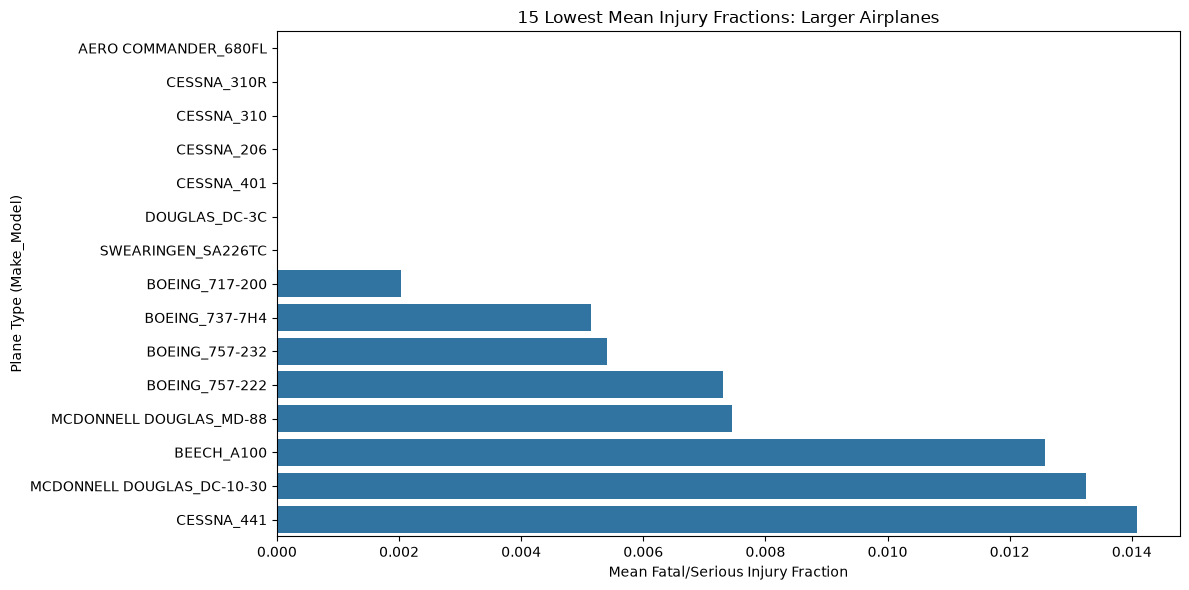

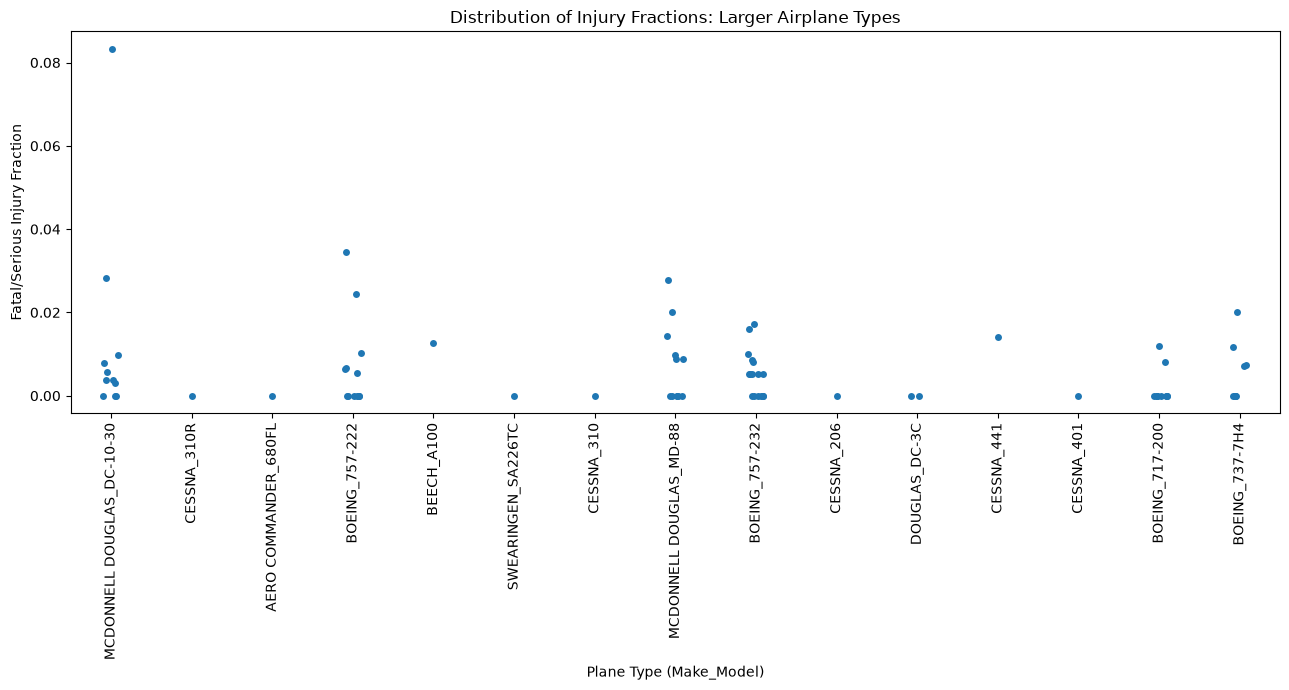

In [25]:

# Analyze plane types: Larger Airplanes

# Keep plane types with at least 10 accident records
plane_type_counts = df["Plane.Type"].value_counts()
valid_plane_types = plane_type_counts[plane_type_counts >= 10].index

large_plane_data = df[
    (df["Plane.Size"] == "Larger Airplanes") &
    (df["Plane.Type"].isin(valid_plane_types))
].copy()

# Calculate mean injury fraction for each plane type
large_plane_risk = (
    large_plane_data.groupby("Plane.Type")["Fatal.Serious.Injury.Rate"]
    .mean()
    .reset_index()
)

# Plot the 15 plane types with the lowest mean injury fractions
large_plane_risk = large_plane_risk.sort_values(
    "Fatal.Serious.Injury.Rate"
).head(15)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=large_plane_risk,
    x="Fatal.Serious.Injury.Rate",
    y="Plane.Type"
)
plt.title("15 Lowest Mean Injury Fractions: Larger Airplanes")
plt.xlabel("Mean Fatal/Serious Injury Fraction")
plt.ylabel("Plane Type (Make_Model)")
plt.tight_layout()
plt.show()

# Distribution plot for these plane types
selected_types = large_plane_risk["Plane.Type"].tolist()

large_distribution = large_plane_data[
    large_plane_data["Plane.Type"].isin(selected_types)
]

plt.figure(figsize=(13, 7))
sns.stripplot(
    data=large_distribution,
    x="Plane.Type",
    y="Fatal.Serious.Injury.Rate",
    jitter=True
)
plt.title("Distribution of Injury Fractions: Larger Airplane Types")
plt.xlabel("Plane Type (Make_Model)")
plt.ylabel("Fatal/Serious Injury Fraction")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

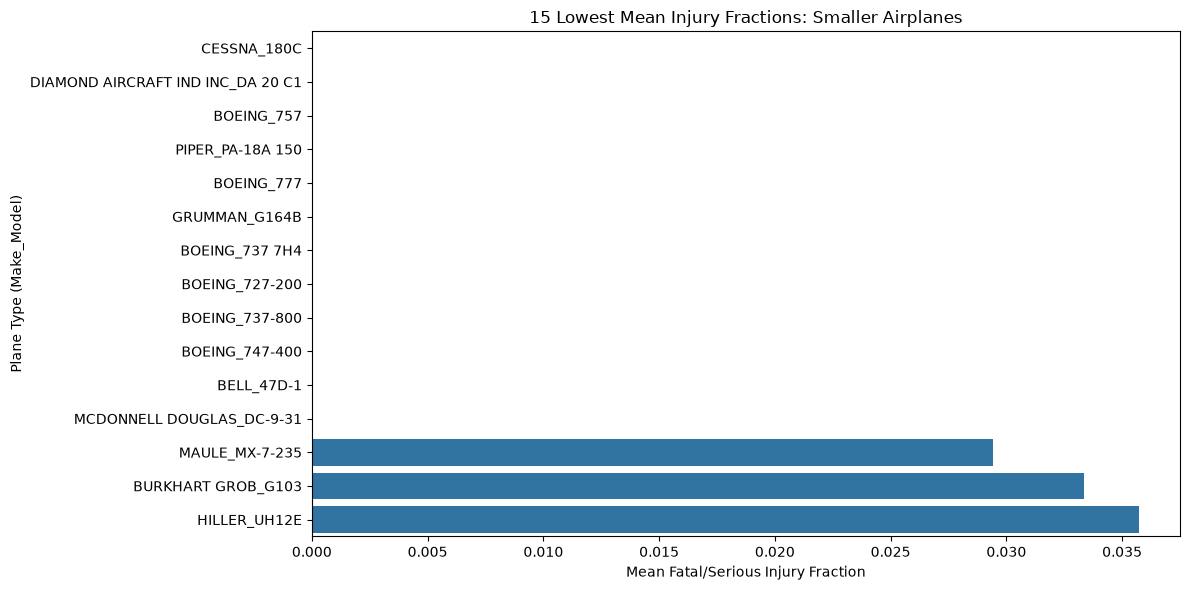

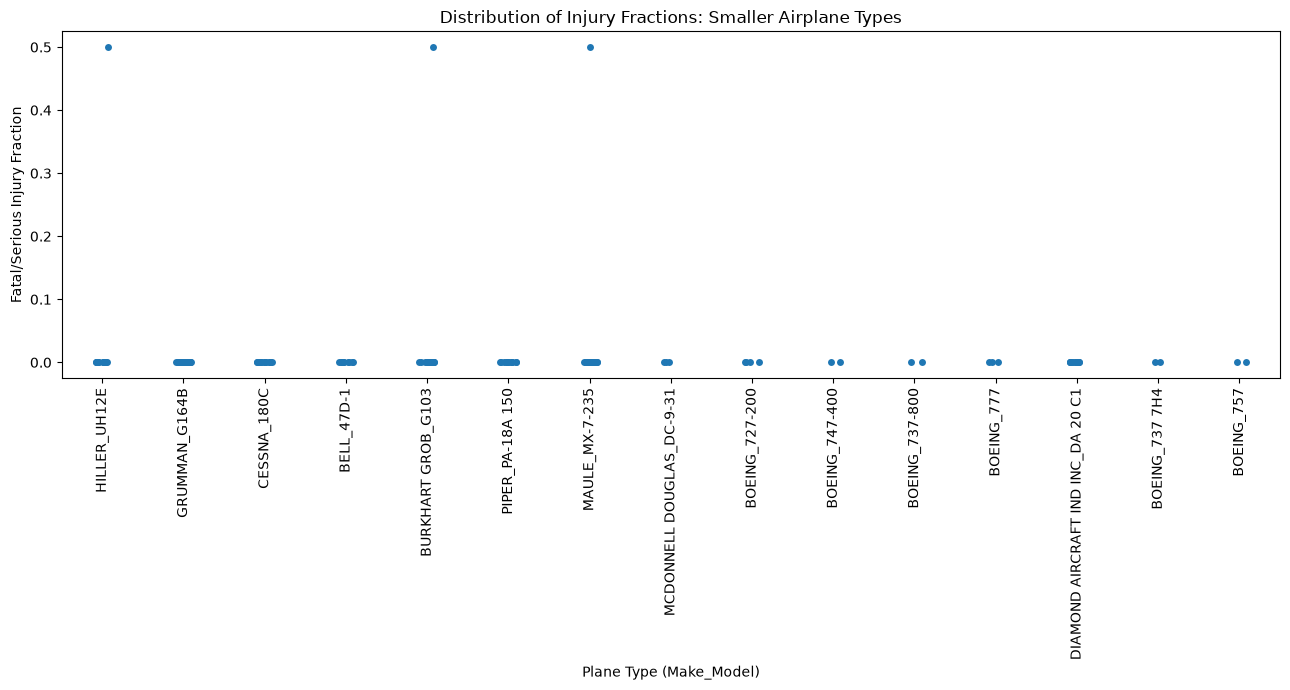

In [26]:

# Analyze plane types: Smaller Airplanes

# Keep plane types with at least 10 accident records
plane_type_counts = df["Plane.Type"].value_counts()
valid_plane_types = plane_type_counts[plane_type_counts >= 10].index

small_plane_data = df[
    (df["Plane.Size"] == "Smaller Airplanes") &
    (df["Plane.Type"].isin(valid_plane_types))
].copy()

# Calculate mean injury fraction for each plane type
small_plane_risk = (
    small_plane_data.groupby("Plane.Type")["Fatal.Serious.Injury.Rate"]
    .mean()
    .reset_index()
)

# Plot the 15 plane types with the lowest mean injury fractions
small_plane_risk = small_plane_risk.sort_values(
    "Fatal.Serious.Injury.Rate"
).head(15)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=small_plane_risk,
    x="Fatal.Serious.Injury.Rate",
    y="Plane.Type"
)
plt.title("15 Lowest Mean Injury Fractions: Smaller Airplanes")
plt.xlabel("Mean Fatal/Serious Injury Fraction")
plt.ylabel("Plane Type (Make_Model)")
plt.tight_layout()
plt.show()

# Distribution plot for these plane types
selected_types = small_plane_risk["Plane.Type"].tolist()

small_distribution = small_plane_data[
    small_plane_data["Plane.Type"].isin(selected_types)
]

plt.figure(figsize=(13, 7))
sns.stripplot(
    data=small_distribution,
    x="Plane.Type",
    y="Fatal.Serious.Injury.Rate",
    jitter=True
)
plt.title("Distribution of Injury Fractions: Smaller Airplane Types")
plt.xlabel("Plane Type (Make_Model)")
plt.ylabel("Fatal/Serious Injury Fraction")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Discussion of Specific Airplane Types
The analysis compared the proportions of fatal or serious injuries across smaller and larger airplane models with at least 10 recorded accidents. It identified models in both groups with relatively low average injury proportions. These figures describe recorded accidents, not risk per flight. Comparisons therefore require caution: accident counts and operating conditions should be considered before making safety recommendations.


### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

Summary by Weather Condition:


,Weather.Condition,Accident_Count,Mean_Injury_Rate,Destruction_Rate
0,IMC,5343,0.665369,0.601448
1,UNK,889,0.627557,0.592814
2,VMC,62058,0.230807,0.178623


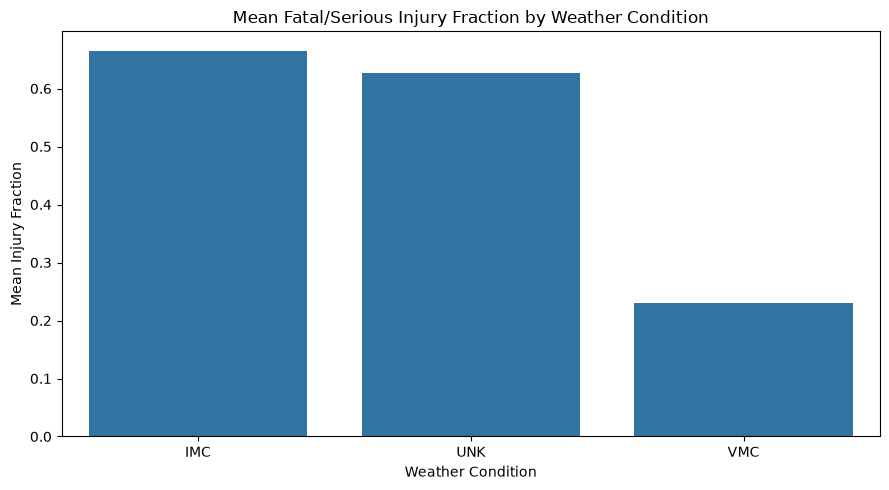

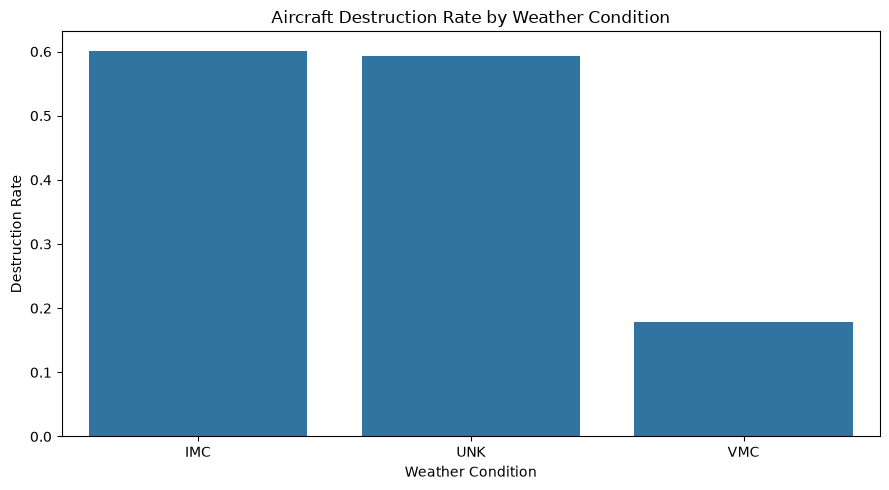

Summary by Number of Engines:


,Number.of.Engines,Accident_Count,Mean_Injury_Rate,Destruction_Rate
0,0.0,779,0.290884,0.160888
1,1.0,57333,0.255899,0.196724
2,2.0,8456,0.339753,0.328422
3,3.0,183,0.072621,0.136364
4,4.0,207,0.234488,0.292398
5,8.0,1,0.421053,0.000000


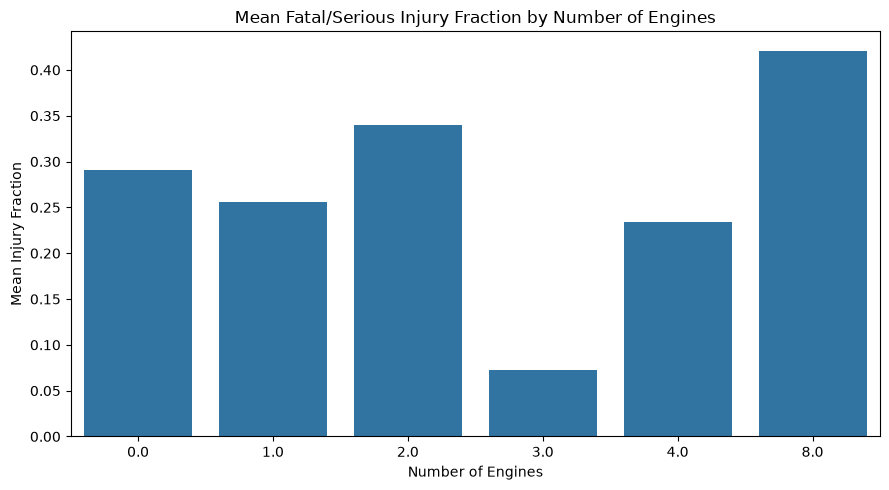

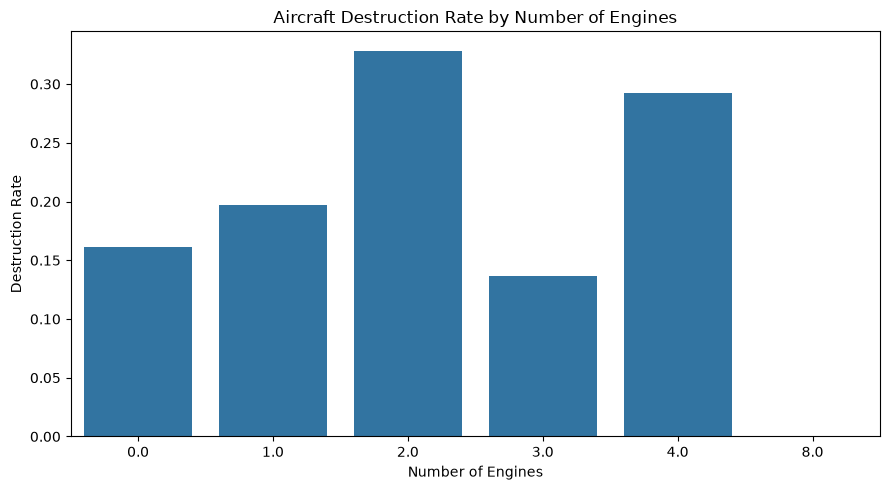

In [27]:

# Exploring Other Variables

# Factor 1: Weather Condition

weather_summary = (
    df.groupby("Weather.Condition")
    .agg(
        Accident_Count=("Event.Id", "count"),
        Mean_Injury_Rate=("Fatal.Serious.Injury.Rate", "mean"),
        Destruction_Rate=("Aircraft.Destroyed", "mean")
    )
    .reset_index()
    .dropna(subset=["Weather.Condition"])
)

print("Summary by Weather Condition:")
display(weather_summary)

# Plot injury rate by weather condition
plt.figure(figsize=(9, 5))
sns.barplot(
    data=weather_summary,
    x="Weather.Condition",
    y="Mean_Injury_Rate"
)
plt.title("Mean Fatal/Serious Injury Fraction by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Mean Injury Fraction")
plt.tight_layout()
plt.show()

# Plot destruction rate by weather condition
plt.figure(figsize=(9, 5))
sns.barplot(
    data=weather_summary,
    x="Weather.Condition",
    y="Destruction_Rate"
)
plt.title("Aircraft Destruction Rate by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Destruction Rate")
plt.tight_layout()
plt.show()


# Factor 2: Number of Engines

engine_summary = (
    df.groupby("Number.of.Engines")
    .agg(
        Accident_Count=("Event.Id", "count"),
        Mean_Injury_Rate=("Fatal.Serious.Injury.Rate", "mean"),
        Destruction_Rate=("Aircraft.Destroyed", "mean")
    )
    .reset_index()
    .dropna(subset=["Number.of.Engines"])
    .sort_values("Number.of.Engines")
)

print("Summary by Number of Engines:")
display(engine_summary)

# Plot injury rate by number of engines
plt.figure(figsize=(9, 5))
sns.barplot(
    data=engine_summary,
    x="Number.of.Engines",
    y="Mean_Injury_Rate"
)
plt.title("Mean Fatal/Serious Injury Fraction by Number of Engines")
plt.xlabel("Number of Engines")
plt.ylabel("Mean Injury Fraction")
plt.tight_layout()
plt.show()

# Plot destruction rate by number of engines
plt.figure(figsize=(9, 5))
sns.barplot(
    data=engine_summary,
    x="Number.of.Engines",
    y="Destruction_Rate"
)
plt.title("Aircraft Destruction Rate by Number of Engines")
plt.xlabel("Number of Engines")
plt.ylabel("Destruction Rate")
plt.tight_layout()
plt.show()
